In [11]:
import pandas as pd
import shutil

ten_cu = "/content/sample_data/customers_clean.csv"
df_eu = pd.read_csv(ten_cu)

print(df_eu.shape)
print(df_eu.columns.tolist())
df_eu.head()

(38765, 4)
['Member_number', 'Date', 'itemDescription', 'month']


,Member_number,Date,itemDescription,month
0,1808,2015-07-21,tropical fruit,2015-07
1,2552,2015-01-05,whole milk,2015-01
2,2300,2015-09-19,pip fruit,2015-09
3,1187,2015-12-12,other vegetables,2015-12
4,3037,2015-02-01,whole milk,2015-02


In [12]:
import time
import warnings
from itertools import combinations
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")

# ===== CẤU HÌNH =====
DATA_CANDIDATES = [Path("customers_clean.csv"),
                   Path("sample_data/customers_clean.csv"),
                   Path("data/customers_clean.csv")]
OUT_DIR = Path("results")
SUPPORTS = [0.001, 0.003, 0.005, 0.0075, 0.010]
CONFS = [0.08, 0.10, 0.12, 0.15]
SO_LAN = 3
S_CHON, C_CHON = 0.001, 0.08


def load_transactions():
    path = next(p for p in DATA_CANDIDATES if p.exists())
    df = pd.read_csv(path, parse_dates=["Date"])
    return (df.groupby(["Member_number", "Date"])["itemDescription"]
              .apply(lambda x: sorted(set(x))).tolist())


def encode(transactions):
    te = TransactionEncoder()
    return pd.DataFrame(te.fit(transactions).transform(transactions),
                        columns=te.columns_)


def apriori_scratch(transactions, min_support):
    n = len(transactions)
    min_count = min_support * n

    counts = {}
    for t in transactions:
        for item in t:
            key = frozenset([item])
            counts[key] = counts.get(key, 0) + 1
    L = {s: c for s, c in counts.items() if c >= min_count}
    result = dict(L)

    k = 2
    while L:
        prev = set(L)
        cand = {}
        for a in prev:
            for b in prev:
                u = a | b
                if len(u) == k and u not in cand:
                    if all(frozenset(s) in prev for s in combinations(u, k - 1)):
                        cand[u] = 0
        for t in transactions:
            if len(t) >= k:
                for c in combinations(t, k):
                    fs = frozenset(c)
                    if fs in cand:
                        cand[fs] += 1
        L = {s: c for s, c in cand.items() if c >= min_count}
        result.update(L)
        k += 1
    return {s: c / n for s, c in result.items()}


def sinh_luat(fi, min_conf, n_trans):
    if len(fi) == 0:
        return pd.DataFrame()
    try:
        return association_rules(fi, metric="confidence", min_threshold=min_conf)
    except TypeError:
        return association_rules(fi, num_itemsets=n_trans,
                                 metric="confidence", min_threshold=min_conf)
    except ValueError:
        return pd.DataFrame()

In [13]:
def chay_thi_nghiem(df_enc, transactions):
    rows = []
    for s in SUPPORTS:
        times = []
        for _ in range(SO_LAN):
            t0 = time.perf_counter()
            fi = apriori(df_enc, min_support=s, use_colnames=True)
            times.append(time.perf_counter() - t0)
        t_lib = sum(times) / len(times)

        t0 = time.perf_counter()
        scratch = apriori_scratch(transactions, s)
        t_scratch = time.perf_counter() - t0

        khop = set(fi["itemsets"]) == set(scratch.keys())
        for c in CONFS:
            rules = sinh_luat(fi, c, len(df_enc))
            rows.append({
                "min_support": s, "min_conf": c,
                "thoi_gian_mlxtend_s": round(t_lib, 4),
                "thoi_gian_tu_cai_dat_s": round(t_scratch, 4),
                "so_tap_pho_bien": len(fi),
                "so_luat": len(rules),
                "khop_tu_cai_dat": khop,
            })
    return pd.DataFrame(rows)


def ve_bieu_do(bang):
    g = bang.drop_duplicates("min_support").sort_values("min_support")
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(g["min_support"], g["thoi_gian_mlxtend_s"], "o-", label="mlxtend")
    ax[0].plot(g["min_support"], g["thoi_gian_tu_cai_dat_s"], "s--", label="tự cài đặt")
    ax[0].set(xscale="log", xlabel="min_support", ylabel="Thời gian (s)",
              title="Thời gian chạy Apriori")
    ax[0].legend()
    ax[1].plot(g["min_support"], g["so_tap_pho_bien"], "o-", color="tab:green")
    ax[1].set(xscale="log", xlabel="min_support", ylabel="Số tập phổ biến",
              title="Số tập phổ biến theo support")
    for a in ax:
        a.invert_xaxis()
        a.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(OUT_DIR / "apriori_hieu_nang.png", dpi=150)


def main():
    OUT_DIR.mkdir(exist_ok=True)
    transactions = load_transactions()
    df_enc = encode(transactions)
    print(f"Transaction: {df_enc.shape[0]} | Mặt hàng: {df_enc.shape[1]} | "
          f"TB mặt hàng/giỏ: {df_enc.sum(axis=1).mean():.2f}")

    bang = chay_thi_nghiem(df_enc, transactions)
    print(bang.to_string(index=False))
    bang.to_csv(OUT_DIR / "apriori_hieu_nang.csv", index=False)
    ve_bieu_do(bang)

    fi = apriori(df_enc, min_support=S_CHON, use_colnames=True)
    rules = sinh_luat(fi, C_CHON, len(df_enc))
    rules = rules[rules["lift"] > 1.0].copy()
    f = lambda x: ", ".join(sorted(x))
    rules["antecedents"] = rules["antecedents"].apply(f)
    rules["consequents"] = rules["consequents"].apply(f)
    cot = ["antecedents", "consequents", "support", "confidence", "lift"]
    rules = rules.sort_values("lift", ascending=False)[cot]
    rules.to_csv(OUT_DIR / "apriori_luat.csv", index=False)
    print(f"\nCấu hình chọn: support={S_CHON}, conf={C_CHON} -> {len(rules)} luật (lift>1)")
    print(rules.head(15).to_string(index=False))

Transaction: 14963 | Mặt hàng: 167 | TB mặt hàng/giỏ: 2.54
 min_support  min_conf  thoi_gian_mlxtend_s  thoi_gian_tu_cai_dat_s  so_tap_pho_bien  so_luat  khop_tu_cai_dat
      0.0010      0.08               3.5795                  0.2384              750      231             True
      0.0010      0.10               3.5795                  0.2384              750      130             True
      0.0010      0.12               3.5795                  0.2384              750       73             True
      0.0010      0.15               3.5795                  0.2384              750       10             True
      0.0030      0.08               1.0007                  0.1349              216       79             True
      0.0030      0.10               1.0007                  0.1349              216       39             True
      0.0030      0.12               1.0007                  0.1349              216       26             True
      0.0030      0.15               1.0007          

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

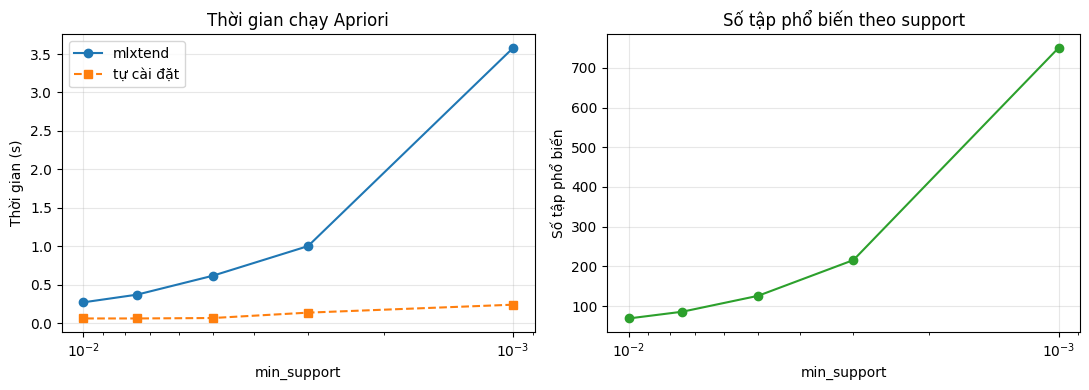

In [14]:
main()

from google.colab import files
for f in ["apriori_hieu_nang.csv", "apriori_luat.csv", "apriori_hieu_nang.png"]:
    files.download(f"results/{f}")